# Regresión lineal con descenso de gradiente

**Materia:** Inteligencia Artificial
**Profesor:** José Mario Ríos Félix
**Alumno:** Jose de Jesus Quintero Noris
**No. de control:** 23170288

Se ajusta una recta a datos reales del dataset California Housing para estimar el valor de una vivienda a partir del ingreso medio de su zona. El modelo se programa desde cero con NumPy. Al final se compara con la solución exacta y se prueba el efecto de cambiar el learning_rate.

## 1. Carga de datos

California Housing viene incluido en scikit-learn. Cada fila es una zona de California. Se usan las primeras 100 zonas.

- X: ingreso medio de la zona (MedInc), en decenas de miles de dólares.
- Y: valor medio de las viviendas (MedHouseVal), en cientos de miles de dólares.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Carga el dataset como tabla
california = fetch_california_housing(as_frame=True)

# X = ingreso medio, Y = valor de la vivienda (primeras 100 zonas)
N_ZONAS = 100
X = california.data['MedInc'].values[:N_ZONAS]
Y = california.target.values[:N_ZONAS]

print(f"Zonas cargadas: {len(X)}")
print(f"Ingreso medio: de {X.min():.2f} a {X.max():.2f}")
print(f"Valor de vivienda: de {Y.min():.2f} a {Y.max():.2f}")

Zonas cargadas: 100
Ingreso medio: de 0.50 a 8.33
Valor de vivienda: de 0.60 a 5.00


## 2. El modelo y sus parámetros

El modelo es una recta: Y = w * X + b.

- `w` es la pendiente: cuánto cambia el valor de la vivienda por cada unidad de ingreso.
- `b` es la ordenada al origen: lo que predice el modelo cuando el ingreso es 0.
- `learning_rate` es el tamaño de cada paso de corrección.
- `epochs` es cuántas veces se repite el entrenamiento.

Se empieza con `w = 0` y `b = 0`, es decir, una recta que todavía no sabe nada.

## 3. Entrenamiento

En cada época se repiten cuatro pasos:

1. **Predecir** con los valores actuales de `w` y `b`.
2. **Medir el error** con el error cuadrático medio (MSE): el promedio de las diferencias entre lo predicho y lo real, elevadas al cuadrado.
3. **Calcular los gradientes** (derivadas del costo respecto a `w` y `b`), que indican hacia dónde moverlos para que el error baje.
4. **Actualizar** `w` y `b` en sentido contrario al gradiente, con pasos de tamaño `learning_rate`.

El proceso se escribe como una función para poder reutilizarlo con distintos `learning_rate` más adelante.

In [2]:
def entrenar(X, Y, learning_rate, epochs):
    """Ajusta Y = w*X + b con descenso de gradiente. Devuelve w, b y el costo de cada época."""
    w, b = 0.0, 0.0
    n = len(X)
    historial_costos = []

    for epoch in range(epochs):
        # 1. Predicción
        Y_pred = w * X + b

        # 2. Costo (MSE)
        error = Y_pred - Y
        costo = np.sum(error ** 2) / (2 * n)
        historial_costos.append(costo)

        # 3. Gradientes
        dw = np.sum(error * X) / n
        db = np.sum(error) / n

        # 4. Actualiza los parámetros
        w = w - learning_rate * dw
        b = b - learning_rate * db

    return w, b, historial_costos

In [3]:
# Hiperparámetros del modelo principal
learning_rate = 0.02
epochs = 5000

w, b, historial_costos = entrenar(X, Y, learning_rate, epochs)

print("Entrenamiento terminado")
print(f"Recta aprendida: Valor = {w:.4f} * Ingreso + {b:.4f}")
print(f"Costo inicial: {historial_costos[0]:.4f}  |  costo final: {historial_costos[-1]:.4f}")

Entrenamiento terminado
Recta aprendida: Valor = 0.3433 * Ingreso + 0.7700
Costo inicial: 1.4661  |  costo final: 0.1955


## 4. Resultado

Los puntos azules son las zonas reales y la línea roja es la recta que aprendió el modelo.

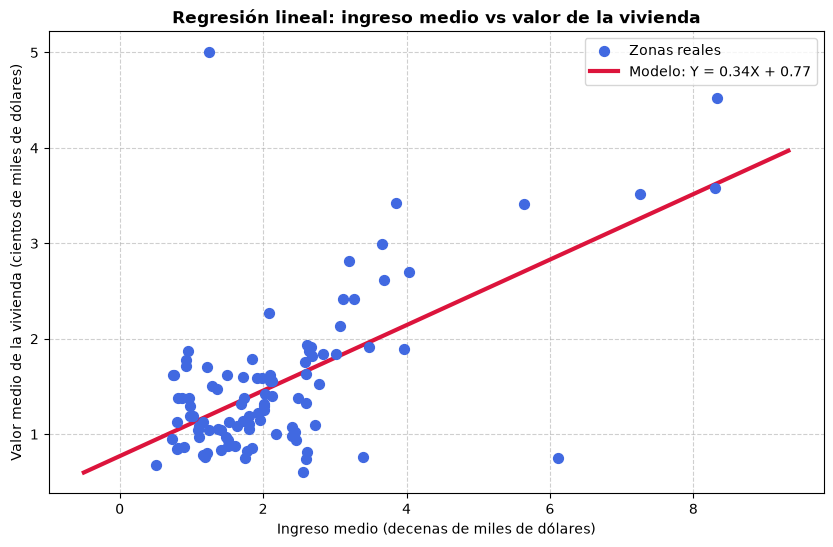

In [4]:
plt.figure(figsize=(10, 6))

# Puntos reales
plt.scatter(X, Y, color='royalblue', s=50, label='Zonas reales', zorder=5)

# Recta aprendida
X_linea = np.linspace(X.min() - 1, X.max() + 1, 100)
plt.plot(X_linea, w * X_linea + b, color='crimson', linewidth=3,
         label=f'Modelo: Y = {w:.2f}X + {b:.2f}')

plt.title('Regresión lineal: ingreso medio vs valor de la vivienda', fontweight='bold')
plt.xlabel('Ingreso medio (decenas de miles de dólares)')
plt.ylabel('Valor medio de la vivienda (cientos de miles de dólares)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 5. Evolución del costo

Si la curva baja y se aplana, el modelo terminó de aprender. Si siguiera bajando en la última época, faltarían épocas. A la derecha se amplían las primeras 200 épocas, donde ocurre la mayor parte del aprendizaje.

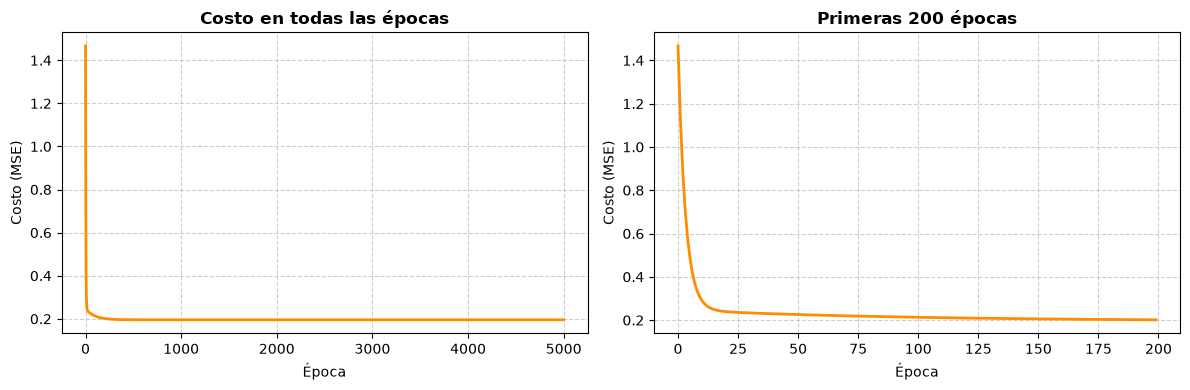

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
ejes[0].set_title('Costo en todas las épocas', fontweight='bold')

ejes[1].plot(range(200), historial_costos[:200], color='darkorange', linewidth=2)
ejes[1].set_title('Primeras 200 épocas', fontweight='bold')

for eje in ejes:
    eje.set_xlabel('Época')
    eje.set_ylabel('Costo (MSE)')
    eje.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 6. Comprobación con la solución exacta

La mejor recta posible para estos datos se puede obtener directamente con mínimos cuadrados (`np.polyfit`). Si el descenso de gradiente funcionó, debe llegar a casi los mismos valores.

In [6]:
# Solución exacta por mínimos cuadrados
w_exacta, b_exacta = np.polyfit(X, Y, 1)

print(f"Descenso de gradiente: w = {w:.4f}, b = {b:.4f}")
print(f"Mínimos cuadrados    : w = {w_exacta:.4f}, b = {b_exacta:.4f}")
print(f"Diferencia           : w = {abs(w - w_exacta):.6f}, b = {abs(b - b_exacta):.6f}")

Descenso de gradiente: w = 0.3433, b = 0.7700
Mínimos cuadrados    : w = 0.3433, b = 0.7700
Diferencia           : w = 0.000000, b = 0.000000


## 7. `learning_rate`

Se entrena otro modelo igual, pero con un paso 20 veces más pequeño (`0.001`). Con pasos muy chicos el modelo avanza más lento y, con las mismas épocas, puede quedarse a medio camino.

learning_rate = 0.02: w = 0.3433, b = 0.7700, costo final = 0.1955
learning_rate = 0.001: w = 0.3944, b = 0.6174, costo final = 0.1990
Solución exacta          : w = 0.3433, b = 0.7700


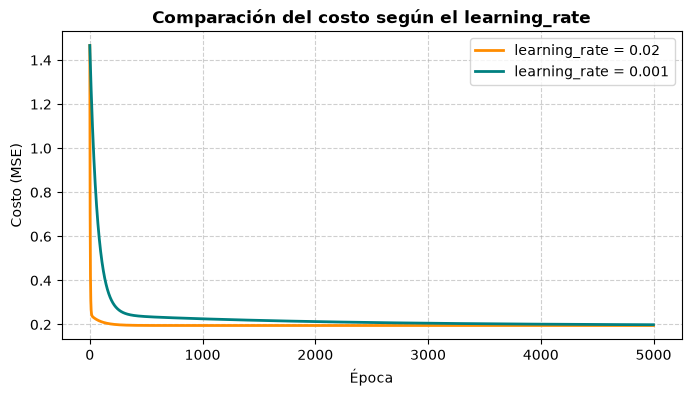

In [7]:
lr_chico = 0.001
w_lento, b_lento, costos_lento = entrenar(X, Y, lr_chico, epochs)

print(f"learning_rate = {learning_rate}: w = {w:.4f}, b = {b:.4f}, costo final = {historial_costos[-1]:.4f}")
print(f"learning_rate = {lr_chico}: w = {w_lento:.4f}, b = {b_lento:.4f}, costo final = {costos_lento[-1]:.4f}")
print(f"Solución exacta          : w = {w_exacta:.4f}, b = {b_exacta:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2, label=f'learning_rate = {learning_rate}')
plt.plot(range(epochs), costos_lento, color='teal', linewidth=2, label=f'learning_rate = {lr_chico}')
plt.title('Comparación del costo según el learning_rate', fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Costo (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 8. Qué tan bueno es el modelo: R²

El coeficiente de determinación **R²** indica qué parte de la variación del valor de las viviendas explica la recta. Vale 1 si la recta pasa por todos los puntos y 0 si no es mejor que predecir siempre el promedio.

In [ ]:
Y_pred = w * X + b
ss_residual = np.sum((Y - Y_pred) ** 2)
ss_total = np.sum((Y - Y.mean()) ** 2)
r2 = 1 - ss_residual / ss_total

print(f"R² = {r2:.3f}")

# Ejemplo de predicción: zona con ingreso medio de 5 (50,000 dólares)
ingreso_ejemplo = 5.0
valor_ejemplo = w * ingreso_ejemplo + b
print(f"Para un ingreso de {ingreso_ejemplo} ({ingreso_ejemplo * 10_000:,.0f} dólares), "
      f"el modelo estima un valor de {valor_ejemplo:.2f} ({valor_ejemplo * 100_000:,.0f} dólares).")

R² = 0.379
Para un ingreso de 5.0 (50,000 dólares), el modelo estima un valor de 2.49 (248,625 dólares).


## Interpretación de los resultados

Las siguientes líneas calculan la interpretación con los valores obtenidos en esta ejecución:

In [ ]:
print(f"Recta aprendida: Valor = {w:.4f} * Ingreso + {b:.4f}")
print()
print(f"- Pendiente: como el ingreso está en decenas de miles de dólares y el valor en cientos de miles, "
      f"por cada 10,000 dólares más de ingreso medio en la zona el modelo estima "
      f"{w * 100_000:,.0f} dólares más en el valor de la vivienda.")
print(f"- Ordenada al origen ({b:.4f}): sería el valor de una vivienda en una zona con ingreso cero. "
      f"El ingreso mínimo de estos datos es {X.min():.2f}, así que ese punto queda fuera del rango observado "
      f"y no tiene una interpretación práctica.")
print(f"- Convergencia: el costo bajó de {historial_costos[0]:.2f} en la primera época a "
      f"{historial_costos[-1]:.4f} al final, y la diferencia con la solución exacta es de "
      f"{abs(w - w_exacta):.6f} en w.")
print(f"- Ajuste: R² = {r2:.3f}, es decir, el ingreso explica aproximadamente {r2 * 100:.0f}% "
      f"de la variación del valor de las viviendas.")

Recta aprendida: Valor = 0.3433 * Ingreso + 0.7700

- Pendiente: como el ingreso está en decenas de miles de dólares y el valor en cientos de miles, por cada 10,000 dólares más de ingreso medio en la zona el modelo estima 34,325 dólares más en el valor de la vivienda.
- Ordenada al origen (0.7700): sería el valor de una vivienda en una zona con ingreso cero. El ingreso mínimo de estos datos es 0.50, así que ese punto queda fuera del rango observado y no tiene una interpretación práctica.
- Convergencia: el costo bajó de 1.47 en la primera época a 0.1955 al final, y la diferencia con la solución exacta es de 0.000000 en w.
- Ajuste: R² = 0.379, es decir, el ingreso explica aproximadamente 38% de la variación del valor de las viviendas.


**Conclusiones**

- El descenso de gradiente llega prácticamente a la misma recta que la solución exacta de mínimos cuadrados, así que la implementación es correcta.
- Una pendiente positiva indica que las zonas con más ingreso tienden a tener viviendas más caras. Los puntos tienen dispersión, por lo que el ingreso por sí solo no explica todo el valor de una vivienda; faltan otras variables (ubicación, edad de las casas, número de cuartos, etc.).
- El learning_rate importa: con un paso demasiado pequeño el modelo aprende muy lento y con las mismas épocas no alcanza la solución; con uno demasiado grande los valores pueden crecer sin control en lugar de converger.